In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "3"

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Q0. Formatting data

In [2]:
#Loading the datasets for the three fonts
F1 = pd.read_csv('character+font+images\\CURLZ.csv')
F2 = pd.read_csv('character+font+images\\JOKERMAN.csv')
F3 = pd.read_csv('character+font+images\\ONYX.csv')
fonts = [F1, F2, F3]

N = 0
for i, font in enumerate(fonts):
    font = font.dropna() # Drop NaN values from each font dataset
    font = font.drop(columns=[ 'fontVariant', 'm_label',  'orientation', 'm_top', 'm_left', 'originalH', 'originalW', 'h', 'w']) # Drop unnecessary columns
    
    # keep only  the cases (= the rows ) for which strength= 0.7  and italic = 0
    font = font[(font['strength'] == 0.7) & (font['italic'] == 0.0)]
    font = font.drop(columns=['strength', 'italic']) # Drop the 'strength' and 'italic' columns
    
    print(f"size of font {font.iloc[0]['font']} is {font.shape[0]}")
    N += font.shape[0] # Update the total count of cases across all fonts
    fonts[i] = font # Update the font dataset in the list with the filtered version

print(f"Total number of cases across all fonts: {N}")



size of font CURLZ is 245
size of font JOKERMAN is 247
size of font ONYX is 236
Total number of cases across all fonts: 728


## Q1. Creating dataset

In [3]:
DATA = pd.DataFrame()

for font in fonts:
    DATA = pd.concat([DATA, font], ignore_index=True) # Concatenate the filtered font datasets into a single DataFrame
DATA.to_csv('DATA.csv', index=False) # Save the combined DataFrame to a CSV file named 'DATA.csv' without the index

# Analyze the distribution of cases across the three fonts
N = DATA.shape[0]
N1 = DATA[DATA['font'] == 'CURLZ'].shape[0]
N2 = DATA[DATA['font'] == 'JOKERMAN'].shape[0]
N3 = DATA[DATA['font'] == 'ONYX'].shape[0]
for font_name, count in zip(['CURLZ', 'JOKERMAN', 'ONYX'], [N1, N2, N3]):
    print(f"Number of cases for font {font_name}: {count}")
    print(f"Proportion of cases for font {font_name}: {count / N:.4f}\n")

Number of cases for font CURLZ: 245
Proportion of cases for font CURLZ: 0.3365

Number of cases for font JOKERMAN: 247
Proportion of cases for font JOKERMAN: 0.3393

Number of cases for font ONYX: 236
Proportion of cases for font ONYX: 0.3242



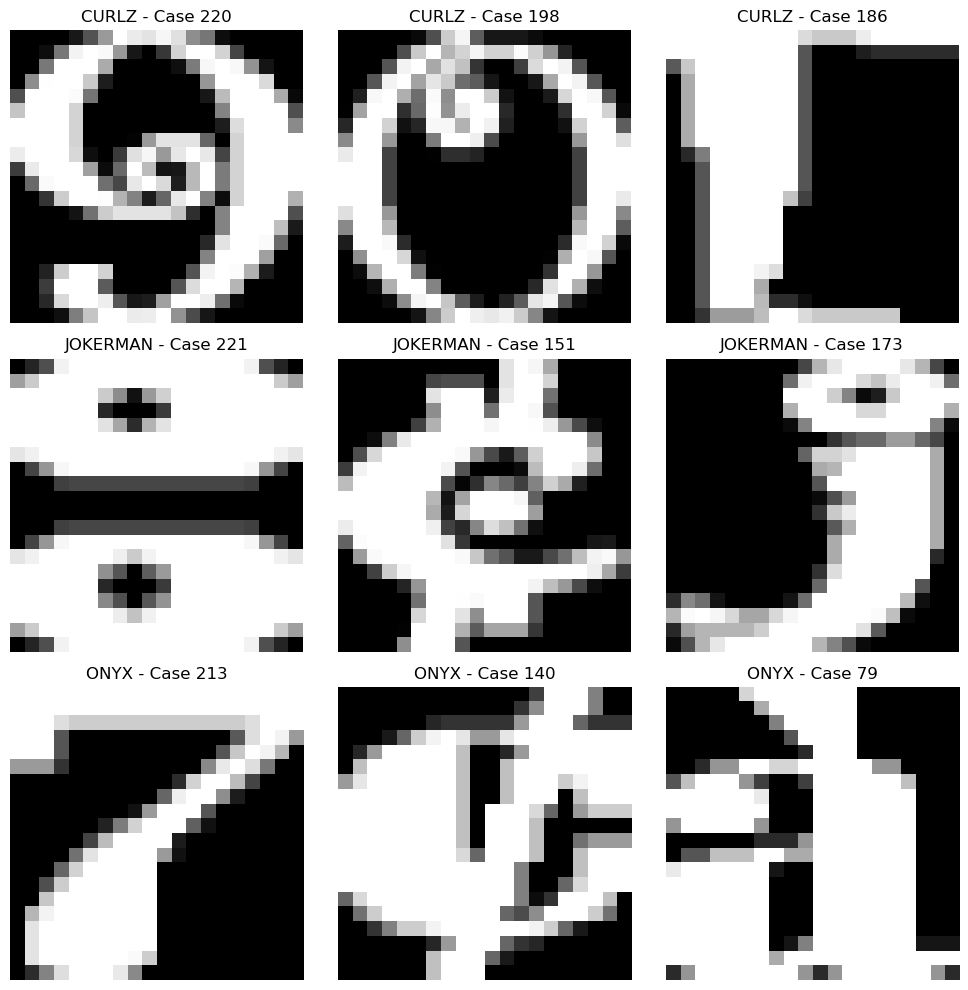

In [4]:
# Selecting 3 cases at random from each font and visualizing them as 20x20 pixel images
full_case_idx = []
for i, font in enumerate(fonts):
    case_idx = np.random.randint(0, font.shape[0], size=3)
    full_case_idx.append([int(idx) for idx in case_idx])

# Creating a 3x3 figure to display the selected cases from each font
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, font in enumerate(fonts):
    for j, idx in enumerate(full_case_idx[i]):
        image_data = font.iloc[idx, 1:].values.astype(np.uint8).reshape(20, 20)
        axes[i, j].imshow(image_data, cmap='gray')
        axes[i, j].set_title(f"{font.iloc[idx]['font']} - Case {idx}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()


## Q2 Evaluating Percentage of Variance Explained

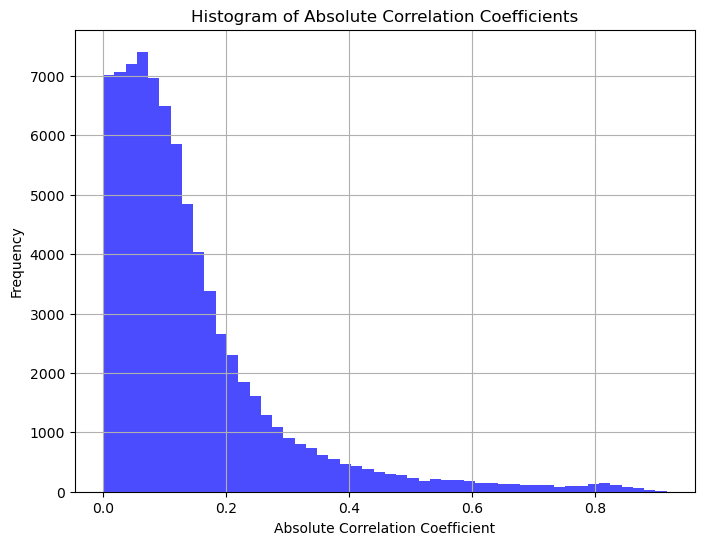

In [5]:
# Assigning the unlabeled cases to a data array and normalizing the data
X = np.array(DATA.drop(columns=['font']).values)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

# Z is the normalized version of X, such that each column of Z has mean 0 and standard deviation 1
Z = (X - X_mean) / X_std
Z_corr = np.corrcoef(Z, rowvar=False) #Z_corr = correlation matrix of Z
abs_corr = np.abs(Z_corr) # Taking absolute value of Z_corr
abs_corr = np.triu(abs_corr, k=1) # Since Z_corr is symmetric we need only the upper triangle of the matrix, excluding the diagonal (k=1)
A = abs_corr.flatten()[abs_corr.flatten() != 0] # Remove zero values from the flattened array of absolute correlation coefficients

# Plotting histogram of the absolute correlation coefficients
fig = plt.figure(figsize=(8, 6))
plt.hist(A, bins=50, color='blue', alpha=0.7)
plt.title('Histogram of Absolute Correlation Coefficients')
plt.xlabel('Absolute Correlation Coefficient')
plt.ylabel('Frequency')
plt.grid()
plt.show()


In [6]:
A_sorted = np.sort(A)
max_corr = A_sorted[-10:] # Get the 10 largest absolute correlation coefficients
min_corr = A_sorted[:10] # Get the 10 smallest absolute correlation coefficients
max_corr_idx = []
min_corr_idx = []
for corr in max_corr:
    idx = np.where(abs_corr == corr)
    max_corr_idx.append((int(idx[0][0]), int(idx[1][0]))) # Append the indices of the features corresponding to the largest correlations
for corr in min_corr:
    idx = np.where(abs_corr == corr)
    min_corr_idx.append((int(idx[0][0]), int(idx[1][0]))) # Append the indices of the features corresponding to the smallest correlations

print(f"indices of the 10 largest abs correlation coefficients:")
# Convert the indices to pixel coordinates and print them along with their corresponding correlation coefficients
for idx in max_corr_idx:
    row1 = idx[0] // 20
    col1 = idx[0] % 20
    row2 = idx[1] // 20
    col2 = idx[1] % 20
    print(f"(r{row1}c{col1}, r{row2}c{col2}) with correlation coefficient {abs_corr[idx]:.4f}")

print("\n")

print(f"indices of the 10 smallest abs correlation coefficients:")
# Convert the indices to pixel coordinates and print them along with their corresponding correlation coefficients
for idx in min_corr_idx:
    row1 = idx[0] // 20
    col1 = idx[0] % 20
    row2 = idx[1] // 20
    col2 = idx[1] % 20
    print(f"(r{row1}c{col1}, r{row2}c{col2}) with correlation coefficient {abs_corr[idx]:.4f}")

indices of the 10 largest abs correlation coefficients:
(r11c1, r12c1) with correlation coefficient 0.8932
(r9c18, r10c18) with correlation coefficient 0.8951
(r0c1, r0c2) with correlation coefficient 0.9042
(r15c17, r16c17) with correlation coefficient 0.9045
(r10c17, r11c17) with correlation coefficient 0.9046
(r0c3, r0c4) with correlation coefficient 0.9047
(r0c0, r0c1) with correlation coefficient 0.9072
(r0c18, r0c19) with correlation coefficient 0.9092
(r12c1, r13c1) with correlation coefficient 0.9108
(r19c18, r19c19) with correlation coefficient 0.9155


indices of the 10 smallest abs correlation coefficients:
(r12c14, r15c8) with correlation coefficient 0.0000
(r3c13, r8c9) with correlation coefficient 0.0000
(r2c1, r11c5) with correlation coefficient 0.0000
(r0c15, r8c16) with correlation coefficient 0.0000
(r13c19, r16c11) with correlation coefficient 0.0000
(r2c18, r19c10) with correlation coefficient 0.0000
(r14c2, r19c1) with correlation coefficient 0.0000
(r2c19, r18c14)

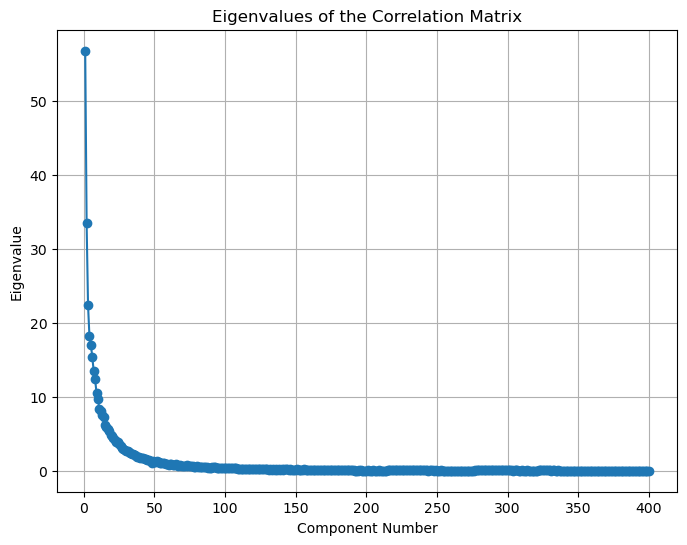

In [7]:
# Here we begin the process of performing PCA on Z


eigenvalues, eigenvectors = np.linalg.eig(Z_corr)
W = eigenvectors # W is the 400x400 column matrix of eigenvectors of Z_corr
m_values = np.arange(1, 401)

# Plotting the eigenvalues of the correlation matrix
# (see figure 3)
figure = plt.figure(figsize=(8, 6))
plt.plot(m_values, eigenvalues, marker='o')
plt.title('Eigenvalues of the Correlation Matrix')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid()
plt.show()

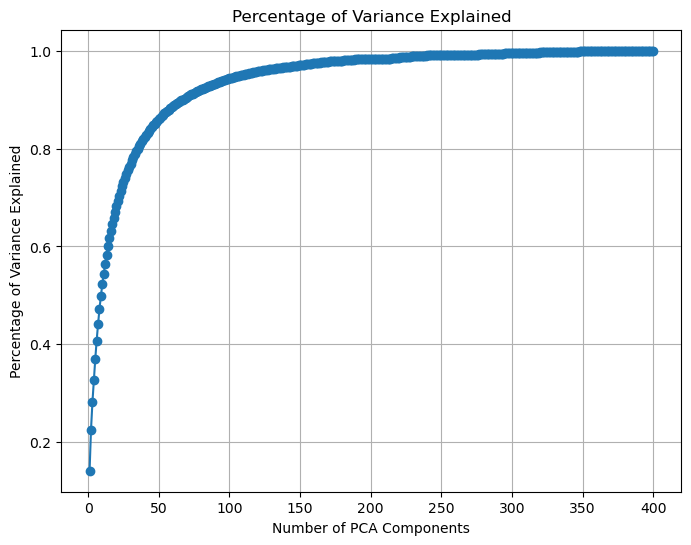

109

In [8]:
# Calculating the percentage of variance explained (PVE) for each number of PCA components

PVE_values = []
for m in range(1, 401):
    PVE = np.sum(eigenvalues[:m]) / 400 # PVE(m) = (sum of the first m eigenvalues) / (total number of features)
    PVE_values.append(PVE)

# Plotting PVE as a function of the number of PCA components
plt.figure(figsize=(8, 6))
plt.plot(m_values, PVE_values, marker='o')
plt.title('Percentage of Variance Explained')
plt.xlabel('Number of PCA Components')
plt.ylabel('Percentage of Variance Explained')
plt.grid()
plt.show()

# Finding the smallest number of PCA components s such that PVE >= 0.95
for m in range(1, 401):
    PVE = np.sum(eigenvalues[:m]) / 400
    if PVE >= 0.95:
        s = m
        break

s # s = 109


In [9]:
# s = 109
W_reduced = W[:, :s] # Reduce the eigenvector matrix W to the first s columns corresponding to the top 109 principal components
U = Z @ W_reduced # U is our new N x 109 data matrix with 109 freatures instead of 400


In [10]:
Q, S, VT = np.linalg.svd(Z, full_matrices=False) # Perform Singular Value Decomposition (SVD) on the normalized data matrix Z
S_r = S[:s]
Z_r = Q[:, :s] @ np.diag(S_r) @ VT[:s, :]
X_r = Z_r * X_std + X_mean # Reconstruct the data matrix using the reduced SVD components and denormalize it

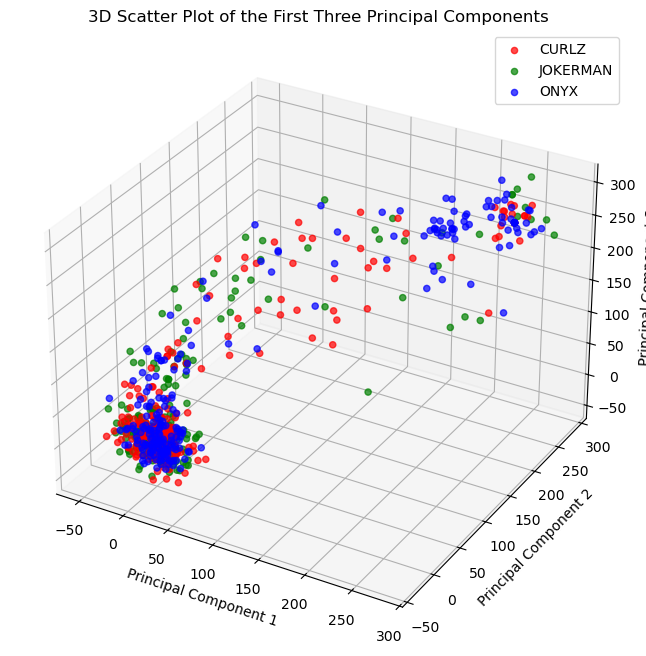

In [11]:
# Now we will visualize the first three principal components of the data in a 3D scatter plot, with different colors for each font
CL1_index = np.where(DATA['font'] == 'CURLZ')[0]
CL2_index = np.where(DATA['font'] == 'JOKERMAN')[0]
CL3_index = np.where(DATA['font'] == 'ONYX')[0]

# Extract the first three principal components for each font using the indices of the cases corresponding to each font
X_1 = X_r[CL1_index, :]
X_2 = X_r[CL2_index, :]
X_3 = X_r[CL3_index, :]

# Plot 3D scatter plot of the first three principal components
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_1[:, 0], X_1[:, 1], X_1[:, 2], c='red', label='CURLZ', alpha=0.7)
ax.scatter(X_2[:, 0], X_2[:, 1], X_2[:, 2], c='green', label='JOKERMAN', alpha=0.7)
ax.scatter(X_3[:, 0], X_3[:, 1], X_3[:, 2], c='blue', label='ONYX', alpha=0.7)
ax.set_title('3D Scatter Plot of the First Three Principal Components')
ax.set_xlabel('Principal Component 1'); ax.set_ylabel('Principal Component 2'); ax.set_zlabel('Principal Component 3')
plt.legend(); plt.show()

## Q5

In [12]:
import os
import time
os.environ["OMP_NUM_THREADS"] = "3" # This was set to stop the warning outputs about too many threads being used by KMeans in sklearn

import sklearn as sk
KMeans = sk.cluster.KMeans
k_values = np.arange(1,21)
k_dispersion = []
comp_times = []

# Running KMeans for k = 1 to 20, with 100 runs for each k, and recording the best dispersion and computation time for each k
for k in k_values:
    start_time = time.time()
    dispersions = []
    for run in range(100):
        # Run KMeans with k clusters, 1 initialization, and random initialization method, and fit it to the data X
        clustering = KMeans(n_clusters=k, n_init=1, init='random').fit(X)
        tot_disp = clustering.inertia_
        dispersions.append(tot_disp)

    best_disp = min(dispersions) 
    print(f"Run {k}: Best Dispersion = {best_disp}")
    k_dispersion.append(best_disp) # Add the smallest dipersion for k to the list of dispersions for each k
    end_time = time.time()
    comp_time = end_time - start_time
    comp_times.append(comp_time)


Run 1: Best Dispersion = 3591604369.361264
Run 2: Best Dispersion = 3249448581.5640287
Run 3: Best Dispersion = 3099132014.2868357
Run 4: Best Dispersion = 3002245766.1564064
Run 5: Best Dispersion = 2927901788.347213
Run 6: Best Dispersion = 2859174060.9108305
Run 7: Best Dispersion = 2796062017.572279
Run 8: Best Dispersion = 2742403051.199918
Run 9: Best Dispersion = 2694420356.6392183
Run 10: Best Dispersion = 2653577845.658849
Run 11: Best Dispersion = 2623416644.1985316
Run 12: Best Dispersion = 2583955829.0695596
Run 13: Best Dispersion = 2550130084.9870367
Run 14: Best Dispersion = 2526847994.4173036
Run 15: Best Dispersion = 2492236373.451238
Run 16: Best Dispersion = 2460673701.3795986
Run 17: Best Dispersion = 2446910306.2337203
Run 18: Best Dispersion = 2423546052.510348
Run 19: Best Dispersion = 2401793553.752319
Run 20: Best Dispersion = 2384316825.816571


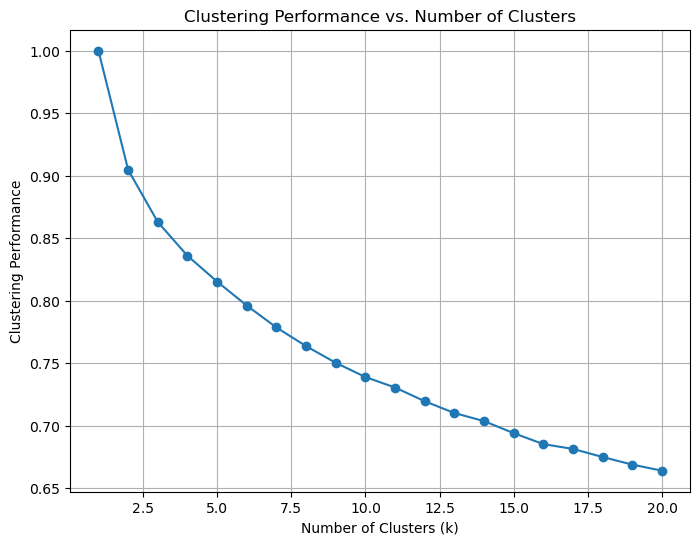

In [13]:
#Creating preformance metric for clustering based on the ratio of the dispersion for k clusters to the dispersion of the whole dataset (k=1)
def perf(disp):
    return disp / k_dispersion[0]

clus_perfs = []
for disp in k_dispersion:
    clus_perf = perf(disp)
    clus_perfs.append(clus_perf)

#Plotting the clustering performance as a function of the number of clusters k
fig = plt.figure(figsize=(8, 6))
plt.plot(k_values, clus_perfs, marker='o')
plt.title('Clustering Performance vs. Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Clustering Performance')
plt.grid()
plt.show()

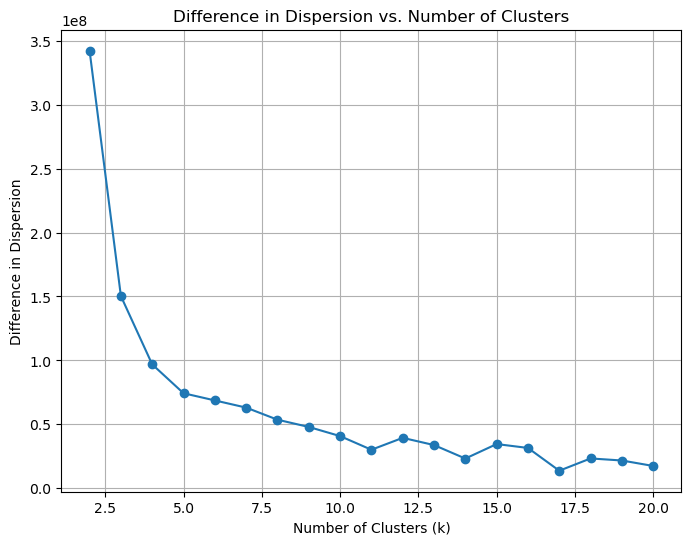

In [14]:
# Calculating the difference in dispersion between k and k-1 clusters for k = 2 to 20
# This will help us identify the "elbow point" in the plot of cluster preformance vs. number of clusters
clus_diff = []
for i in range(1, len(k_dispersion)):
    diff = k_dispersion[i-1] - k_dispersion[i]
    clus_diff.append(diff)

# Plotting the difference in dispersion vs. number of clusters k
fig = plt.figure(figsize=(8, 6))
plt.plot(k_values[1:], clus_diff, marker='o')
plt.title('Difference in Dispersion vs. Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Difference in Dispersion')
plt.grid()
plt.show()

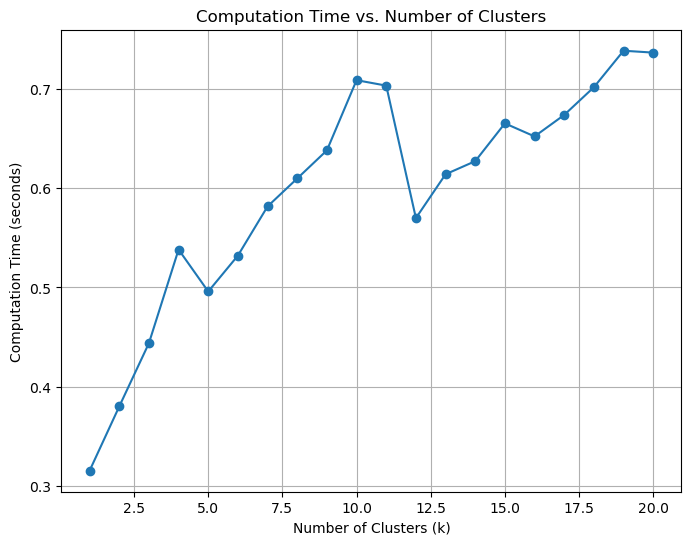

In [15]:
# Plotting the computation time vs. number of clusters k
fig = plt.figure(figsize=(8, 6))
plt.plot(k_values, comp_times, marker='o')
plt.title('Computation Time vs. Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Computation Time (seconds)')
plt.grid()
plt.show()

### Based on the preformance curve and the elbow rule, the best suitable k values is k=7

## Q6

In [16]:
# The elbow point was identified as k=3, so we will run KMeans with k=3 and 100 initializations to get the best clustering performance for k=3
K_Clusters = KMeans(n_clusters=3, n_init=100, init='random').fit(X)
disp = K_Clusters.inertia_
K_cluster_perf = perf(disp) # Calculate the clustering performance for k=3 using the perf function defined earlier
print(f"Clustering performance for k=3 with 100 initializations: {K_cluster_perf:.4f}")

# Extracting the clusters G1, G2, and G3 from the data X based on the labels assigned by KMeans for k=3
G1 = X[K_Clusters.labels_ == 0]
G2 = X[K_Clusters.labels_ == 1]
G3 = X[K_Clusters.labels_ == 2]
G = [G1, G2, G3]




Clustering performance for k=3 with 100 initializations: 0.8629


In [17]:
# Calculates centroid of a cluster G
def centroid(G):
    return np.mean(G, axis=0)

# Calculates the dispersion of a cluster G
def dispersion(G):
    c = centroid(G)
    return np.sum(np.linalg.norm(G - c, axis=1)**2)

# For each cluster G1, G2, and G3, we will calculate the relative size, relative dispersion, and radius of the cluster, and print the results
for i, group in enumerate(G):
    relsize = group.shape[0] / X.shape[0]
    reldispersion = dispersion(group) / disp
    radius = np.sqrt(dispersion(group)/group.shape[0])

    print(f"G{i} - Group size: {group.shape[0]},\n Relative Size: {relsize:.4f},\n Relative Dispersion: {reldispersion:.4f},\n Radius: {radius:.4f}\n")

G0 - Group size: 201,
 Relative Size: 0.2761,
 Relative Dispersion: 0.2651,
 Radius: 2021.8842

G1 - Group size: 295,
 Relative Size: 0.4052,
 Relative Dispersion: 0.4360,
 Radius: 2140.2947

G2 - Group size: 232,
 Relative Size: 0.3187,
 Relative Dispersion: 0.2988,
 Radius: 1997.9372



## Q7

In [27]:
# Centroids for each cluster G1, G2, and G3
g1 = centroid(G1)
g2 = centroid(G2)
g3 = centroid(G3)
centers = [g1, g2, g3]

# Calculate the radius of each cluster as the square root of the dispersion of the cluster
rad_g1 = np.sqrt(dispersion(G1)/G1.shape[0])
rad_g2 = np.sqrt(dispersion(G2)/G2.shape[0])
rad_g3 = np.sqrt(dispersion(G3)/G3.shape[0])
radii = [rad_g1, rad_g2, rad_g3]

pd.DataFrame(centers, columns=DATA.columns[1:]).to_csv('centroids.csv', index=False) # Storing centroids into a csv file

#Compute the kxk matrix Q of distances between the centroids of the clusters
Q = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        Q[i, j] = np.linalg.norm(centers[i] - centers[j])

print(f"Q Matrix:\n{Q}\n")

#Calculates the separability between clusters i and j
def sep(i, j):
    return Q[i, j] / (radii[i] + radii[j])

# Create a 3x3 seprability matrix where the entry (i, j) is the separability between clusters i and j
separability = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        if i != j:
            separability[i, j] = sep(i, j)
print(f"Separability Matrix:\n{separability}\n")

Q Matrix:
[[   0.         1185.73665446 1536.26301038]
 [1185.73665446    0.         1553.15156337]
 [1536.26301038 1553.15156337    0.        ]]

Separability Matrix:
[[0.         0.28488363 0.38217195]
 [0.28488363 0.         0.37531767]
 [0.38217195 0.37531767 0.        ]]



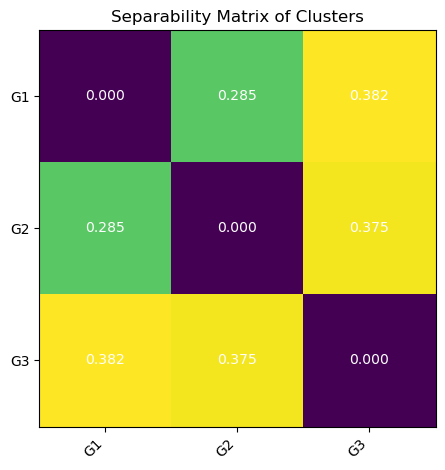

In [28]:

# Lable for axes of the heatmap
x_labels = ['G1', 'G2', 'G3']
y_labels = ['G1', 'G2', 'G3']

# Plotting the heatmap of the frequency matrix with the values displayed in each cell
fig, ax = plt.subplots()
im = ax.imshow(separability, cmap='viridis')

ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.set_yticks(range(len(y_labels)))
ax.set_yticklabels(y_labels)

for i in range(len(y_labels)):
    for j in range(len(x_labels)):
        ax.text(j, i, f"{separability[i, j]:.3f}",
                ha="center", va="center", color="w")

ax.set_title("Separability Matrix of Clusters")
fig.tight_layout()
plt.show()

## Q8

In [20]:
# Creating a function that returns the intersection of the rows of two matrices A and B
def row_intersection(A, B):
    A_set = set(map(tuple, A))
    B_set = set(map(tuple, B))
    intersection = A_set.intersection(B_set)
    return np.array(list(intersection))

In [29]:
#Calculates the frequency of one set (CL) in another set (G)
def freq(G, CL):
    G_size = G.shape[0]
    intersection_size = row_intersection(G, CL).shape[0]
    return intersection_size / G_size

# Assigning the cases for each font to separate arrays and dropping the 'font' column
CL1 = DATA[DATA['font']=='CURLZ'].drop(columns=['font']).values
CL2 = DATA[DATA['font']=='JOKERMAN'].drop(columns=['font']).values
CL3 = DATA[DATA['font']=='ONYX'].drop(columns=['font']).values
HIC = [CL1, CL2, CL3] # High interest clustering corresponding to the three fonts

# Creating a 3x3 frequency matrix where the entry (i, j) is the frequency of class j in cluster i
freq_matrix = np.zeros((3, 3))
for i, CL_i in enumerate(HIC):
    for j, G_i in enumerate(G):
        freq_matrix[i, j] = freq(G_i, CL_i)

# Calculating the purity of each cluster
purity = np.zeros(3)
for j in range(3):
    gini = 0
    for i in range(3):
        gini += freq_matrix[i, j] * (1 - freq_matrix[i, j])
    purity[j] = 1 - gini
print(f"Purity of each cluster: {purity}\n")


Purity of each cluster: [0.37036212 0.43715024 0.41685865]



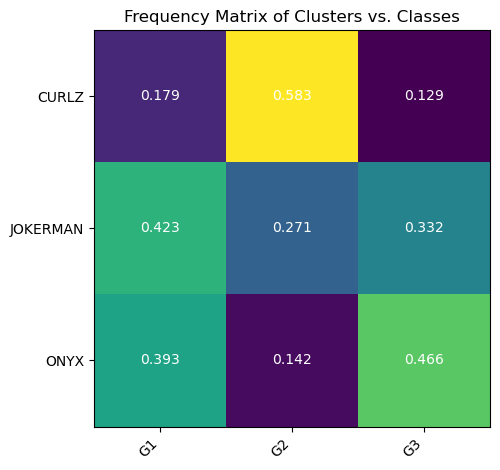

In [30]:
# Display the frequency matrix as a heatmap with the values of the frequencies displayed in each cell

# Lable for axes of the heatmap
x_labels = ['G1', 'G2', 'G3']
y_labels = ['CURLZ', 'JOKERMAN', 'ONYX']

# Rounding the frequency matrix to 3 decimal places for better visualization in the heatmap
freq_matrix_rounded = np.round(freq_matrix, 3)

# Plotting the heatmap of the frequency matrix with the values displayed in each cell
fig, ax = plt.subplots()
im = ax.imshow(freq_matrix_rounded)

ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.set_yticks(range(len(y_labels)))
ax.set_yticklabels(y_labels)

for i in range(len(y_labels)):
    for j in range(len(x_labels)):
        ax.text(j, i, f"{freq_matrix_rounded[i, j]:.3f}",
                ha="center", va="center", color="w")

ax.set_title("Frequency Matrix of Clusters vs. Classes")
fig.tight_layout()
plt.show()

### Purest cluster G is $G_2$ with purity 0.363
### Highest frequency among classes with respect to $G_2$ is with class JOKERMAN with frequenct 0.422

In [23]:
# Creating a function that returns the set difference A - B of two matricies A and B
def set_diff(A, B):
    A_set = set(map(tuple, A))
    B_set = set(map(tuple, B))
    diff = A_set.difference(B_set)
    return np.array(list(diff))

print(f"CL2 - G1:\n{set_diff(CL1, G3).shape[0]}\n") # CL2 - G1
print(f"G2 - CL2:\n{set_diff(G3, CL1).shape[0]}\n") # G1 - CL2

CL2 - G1:
208

G2 - CL2:
183



## Q9

In [24]:
# Calculating the centroids, dispersions, total dispersion, and performance for the high interest clustering (HIC) corresponding to the three fonts
HIC_centroids = [centroid(CL1), centroid(CL2), centroid(CL3)]
HIC_dispersions = np.array([dispersion(CL1), dispersion(CL2), dispersion(CL3)])
HIC_total_dispersion = sum(HIC_dispersions)
HIC_performance = perf(HIC_total_dispersion)

print(f"HIC dispersions:\n{HIC_dispersions}\n")
print(f"HIC total dispersion: {HIC_total_dispersion}\n")
print(f"HIC performance: {HIC_performance}\n")

HIC dispersions:
[1.18911638e+09 1.13413085e+09 1.13088183e+09]

HIC total dispersion: 3454129064.1514163

HIC performance: 0.9617231490242627



## Q11

In [25]:
# Creating new clustering U using HIC centroids as the initial centroids for KMeans with k=3
U_Clusters = KMeans(n_clusters=3, n_init=1, init=HIC_centroids).fit(X)

U_perf = perf(U_Clusters.inertia_) # Calculating preformance of U
print(f"Clustering performance for k=3 with HIC centroids: {U_perf:.4f}\n")

# Extracting the clusters U1, U2, and U3 from the data X based on the labels assigned by KMeans for k=3 with HIC centroids
U1 = X[U_Clusters.labels_ == 0]
U2 = X[U_Clusters.labels_ == 1]
U3 = X[U_Clusters.labels_ == 2]
U = [U1, U2, U3]

# Creating a 3x3 frequency matrix where the entry (i, j) is the frequency of class j in cluster i for the new clustering U
U_freq_matrix = np.zeros((3, 3))
for i, CL_i in enumerate(HIC):
    for j, U_i in enumerate(U):
        U_freq_matrix[i, j] = freq(U_i, CL_i)

Clustering performance for k=3 with HIC centroids: 0.8630



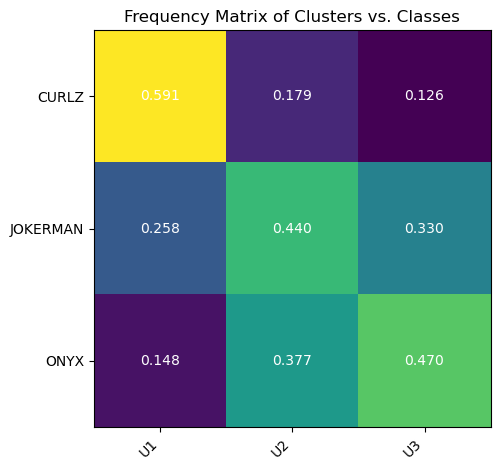

In [51]:
# Display the frequency matrix for the new clustering U as a heatmap with the values of the frequencies displayed in each cell

# Lable for axes of the heatmap
x_labels = ['U1', 'U2', 'U3']
y_labels = ['CURLZ', 'JOKERMAN', 'ONYX']

freq_matrix_rounded = np.round(U_freq_matrix, 3)

# Plotting the heatmap of the frequency matrix with the values displayed in each cell
fig, ax = plt.subplots()
im = ax.imshow(freq_matrix_rounded)

ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.set_yticks(range(len(y_labels)))
ax.set_yticklabels(y_labels)

for i in range(len(y_labels)):
    for j in range(len(x_labels)):
        ax.text(j, i, f"{freq_matrix_rounded[i, j]:.3f}",
                ha="center", va="center", color="w")

ax.set_title("Frequency Matrix of Clusters vs. Classes")
fig.tight_layout()
plt.show()